# Dashboard Intensive Care

Dit notebook is het dashboard voor de verpleegkundigen van de Intensive Care
(zie `requirements.md`). Het dashboard leest de data mart `data/dm_icu.csv`.
Die data mart is het eindpunt van de data pipeline: jullie data warehouse
moet deze tabel kunnen vullen.

Het dashboard heeft twee delen:

1. **Overzicht** (US1, FR1, FR3): een grafiek per patiënt met de meetwaarden
   van de laatste 30 minuten.
2. **Patiëntinformatie** (US2, FR2): kies een patiënt en bekijk de extra
   informatie, zoals de observatie en de pijnscore.

Voer het notebook uit van boven naar beneden (*Run All*).

## De data mart

De data mart is één platte tabel. Elke rij is één meting (één minuut) van
één patiënt. De patiëntgegevens en de observatie staan op elke rij van die
patiënt herhaald.

| Kolom | Betekenis |
|---|---|
| `pid` | patiëntnummer |
| `firstname`, `lastname` | naam van de patiënt |
| `dob` | geboortedatum |
| `treatment` | hoofdbehandeling |
| `bid` | bednummer |
| `mid` | machinenummer |
| `ts` | tijdstip van de meting |
| `sbp`, `dbp` | bloeddruk: bovendruk en onderdruk (mmHg) |
| `hr` | hartslag (slagen per minuut) |
| `fluids` | vloeistoffen toegediend (ml) |
| `blood_given` | bloed toegediend (ml) |
| `blood_lost` | bloed verloren (ml) |
| `note_ts` | tijdstip van de observatie |
| `note_text` | tekst van de observatie |
| `pain_score` | pijnscore (0–10) |

Een lege meetwaarde betekent dat de machine op dat moment niets heeft
gemeten. Het dashboard vult zulke waarden niet zelf in: in de grafiek zie
je dan een onderbreking in de lijn.

In [2]:
"""ICU dashboard: setup, data loading and plot style."""

import textwrap
from pathlib import Path

import ipywidgets as widgets
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

DATA_MART = Path("../data/dm_icu.csv")

# Chart colours and ink (colourblind-safe categorical slots)
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"

# Series per panel: (column, label, colour)
VITALS = [
    ("hr", "Hartslag (bpm)", "#2a78d6"),
    ("sbp", "Bovendruk (mmHg)", "#eb6834"),
    ("dbp", "Onderdruk (mmHg)", "#1baf7a"),
]
FLUIDS = [
    ("fluids", "Vloeistoffen toegediend (ml)", "#6250d6"),
    ("blood_given", "Bloed toegediend (ml)", "#e87ba4"),
    ("blood_lost", "Bloed verloren (ml)", "#008300"),
]

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.grid": True,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "xtick.labelcolor": INK_SECONDARY,
    "ytick.labelcolor": INK_SECONDARY,
    "font.size": 9,
    "lines.linewidth": 1.6,
    "lines.solid_capstyle": "round",
    "lines.solid_joinstyle": "round",
})

dm = pd.read_csv(DATA_MART, parse_dates=["ts", "note_ts", "dob"])
print(f"{len(dm)} metingen van {dm['pid'].nunique()} patiënten ingelezen")

593 metingen van 20 patiënten ingelezen


## Hulpfuncties

De functies hieronder maken de grafieken. Je hoeft ze niet aan te passen.

In [3]:
def last_30_minutes(df: pd.DataFrame) -> pd.DataFrame:
    """Keep the most recent 30 minutes of measurements per patient (FR3).

    Input: data mart rows. Output: the subset within each patient's window.
    """
    window_end = df.groupby("pid")["ts"].transform("max")
    return df[df["ts"] > window_end - pd.Timedelta(minutes=30)]


def measurement_series(patient: pd.DataFrame) -> pd.DataFrame:
    """Return one patient's measurements on a complete one-minute grid.

    Input: data mart rows of one patient. Output: DataFrame indexed by ts.
    Missing minutes become empty rows, so the line shows a gap instead of
    silently connecting the points around it.
    """
    series = patient.set_index("ts").sort_index()
    grid = pd.date_range(series.index.min(), series.index.max(), freq="min")
    columns = [col for col, _, _ in VITALS + FLUIDS]
    return series[columns].reindex(grid)


def plot_panel(ax, series: pd.DataFrame, lines: list, ylim: tuple) -> None:
    """Draw one panel (vitals or fluids) of a patient chart.

    Inputs: matplotlib axes, the patient's measurement grid, the list of
    (column, label, colour) to draw, and the shared y-axis limits.
    """
    for col, label, colour in lines:
        ax.plot(series.index, series[col], color=colour, label=label)
    ax.set_ylim(*ylim)
    ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, 10)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.tick_params(length=0)


def patient_title(patient: pd.DataFrame, width: int) -> str:
    """Return the chart title: bed, name and wrapped main treatment (FR1).

    Inputs: data mart rows of one patient, wrap width in characters.
    """
    first = patient.iloc[0]
    treatment = textwrap.fill(first["treatment"], width)
    return (f"Bed {first['bid']} · {first['firstname']} {first['lastname']}"
            f"\n{treatment}")


def shared_limits(df: pd.DataFrame, lines: list) -> tuple:
    """Return y-axis limits shared by all patients for a set of series.

    Using the same scale for every patient makes the charts comparable.
    """
    values = df[[col for col, _, _ in lines]]
    low, high = values.min().min(), values.max().max()
    margin = (high - low) * 0.05
    return (max(0, low - margin), high + margin)


def add_legend(fig, y: float) -> None:
    """Add one shared legend for both panels at height y of the figure."""
    handles = [plt.Line2D([], [], color=colour, linewidth=2, label=label)
               for _, label, colour in VITALS + FLUIDS]
    fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False,
               bbox_to_anchor=(0.5, y), fontsize=10, labelcolor=INK)

## 1. Overzicht van alle patiënten (US1, FR1, FR3)

Elke patiënt heeft een eigen grafiek. Boven de grafiek staan het bednummer,
de naam en de hoofdbehandeling. De patiënten staan op volgorde van
bednummer.

Elke grafiek heeft twee delen met dezelfde tijdas:

- **boven**: hartslag en bloeddruk (bovendruk en onderdruk);
- **onder**: vloeistoffen toegediend, bloed toegediend en bloed verloren.

Deze twee groepen meetwaarden hebben een heel andere schaal. Hartslag en
bloeddruk liggen tussen ongeveer 50 en 175. De hoeveelheden vloeistof en
bloed liggen tussen 0 en 5. In één grafiek zouden die laatste lijnen plat
op de bodem liggen. Daarom staan ze in een apart deel.

Alle patiënten hebben dezelfde schaal op de y-as. Zo kun je de patiënten
goed met elkaar vergelijken.

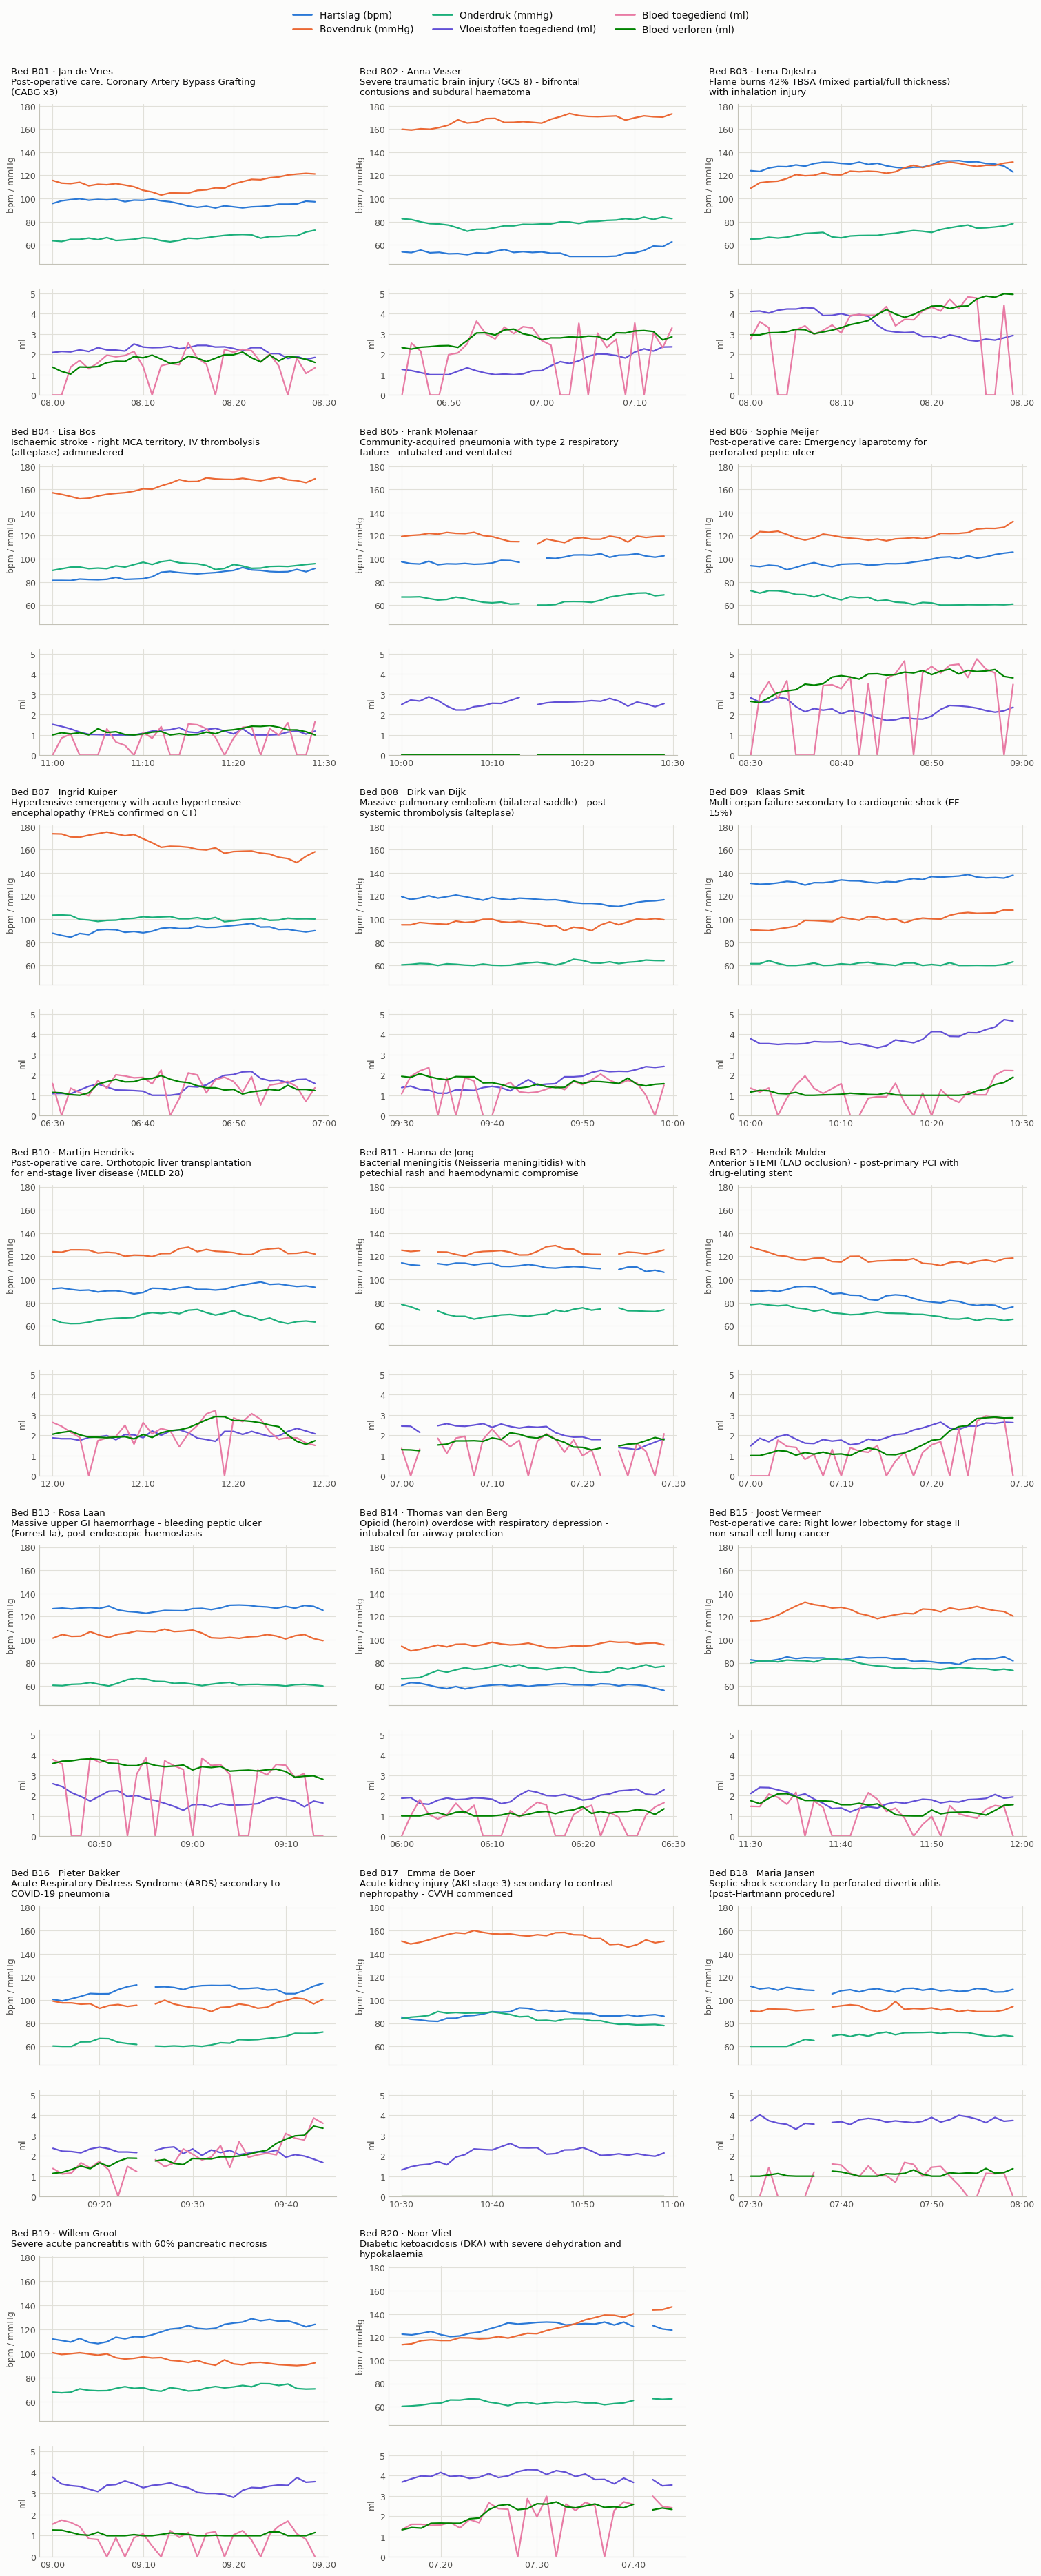

In [4]:
recent = last_30_minutes(dm)
vitals_ylim = shared_limits(recent, VITALS)
fluids_ylim = shared_limits(recent, FLUIDS)

beds = sorted(recent["bid"].unique())
n_cols = 3
n_rows = -(-len(beds) // n_cols)  # round up

fig = plt.figure(figsize=(15, 5.2 * n_rows), layout="constrained")
subfigs = fig.subfigures(n_rows, n_cols, wspace=0.04, hspace=0.04)

for subfig, bed in zip(subfigs.flat, beds):
    patient = recent[recent["bid"] == bed]
    series = measurement_series(patient)
    ax_vitals, ax_fluids = subfig.subplots(
        2, 1, sharex=True, height_ratios=[3, 2])
    plot_panel(ax_vitals, series, VITALS, vitals_ylim)
    plot_panel(ax_fluids, series, FLUIDS, fluids_ylim)
    ax_vitals.set_ylabel("bpm / mmHg")
    ax_fluids.set_ylabel("ml")
    subfig.suptitle(patient_title(patient, 55), x=0.02, ha="left",
                    fontsize=9.5, color=INK)

for subfig in subfigs.flat[len(beds):]:
    subfig.set_visible(False)

add_legend(fig, 1.025)
plt.show()

## 2. Informatie per patiënt (US2, FR2)

Kies een patiënt in de keuzelijst. Je ziet dan:

- de gegevens van de patiënt: geboortedatum, bednummer, machinenummer en
  hoofdbehandeling;
- de laatste observatie met de pijnscore;
- een grote grafiek van de laatste 30 minuten;
- een tabel met alle meetwaarden. In de tabel kun je de precieze waarden
  aflezen.

**LET OP:** de keuzelijst werkt alleen als je het notebook zelf uitvoert.
In een voorbeeldweergave (bijvoorbeeld op GitHub) zie je hem niet.

In [5]:
def show_patient(bid: str) -> None:
    """Show the detail view (FR2) for the patient in bed bid."""
    patient = recent[recent["bid"] == bid]
    first = patient.iloc[0]
    dob = (first["dob"].strftime("%d-%m-%Y") if pd.notna(first["dob"])
           else "onbekend")
    note_ts = (first["note_ts"].strftime("%d-%m-%Y %H:%M")
               if pd.notna(first["note_ts"]) else "geen observatie")

    display(Markdown(f"""
### {first['firstname']} {first['lastname']}

| | |
|---|---|
| **Geboortedatum** | {dob} |
| **Bednummer** | {first['bid']} |
| **Machinenummer** | {first['mid']} |
| **Hoofdbehandeling** | {first['treatment']} |
| **Pijnscore** | {first['pain_score']} (0–10) |

**Observatie** ({note_ts}):

> {first['note_text']}
"""))

    series = measurement_series(patient)
    fig, (ax_vitals, ax_fluids) = plt.subplots(
        2, 1, sharex=True, figsize=(11, 6.5), height_ratios=[3, 2],
        layout="constrained")
    plot_panel(ax_vitals, series, VITALS, vitals_ylim)
    plot_panel(ax_fluids, series, FLUIDS, fluids_ylim)
    ax_vitals.set_ylabel("bpm / mmHg")
    ax_fluids.set_ylabel("ml")
    ax_fluids.set_xlabel("Tijd")
    add_legend(fig, 1.12)
    plt.show()

    table = series.rename(columns={col: label
                                   for col, label, _ in VITALS + FLUIDS})
    table.index = table.index.strftime("%H:%M")
    table.index.name = "Tijd"
    display(table.style.format(precision=1, na_rep="–"))


options = [(f"Bed {row.bid} · {row.firstname} {row.lastname}", row.bid)
           for row in recent.drop_duplicates("bid").sort_values("bid")
           .itertuples()]
widgets.interact(show_patient,
                 bid=widgets.Dropdown(options=options, description="Patiënt"));

interactive(children=(Dropdown(description='Patiënt', options=(('Bed B01 · Jan de Vries', 'B01'), ('Bed B02 · …